### What are the nulti-Agent RAG Systems ?

A multi-Agent RAG sustem splits pipeline into multiple specialized agents - each responsible for a specific role and enables them to collaborate on a single query or  task

Multi-Agent RAG system with LangGraph

Trasform your documents into seachable knowledge base that can snwer questions intelligently using AI. Simply upload documents and ask questions in natural language- the system finds the relevent information and generates comprehensive answers.

KeyFeatures

1. Multi-format Support : Handles pdf and text documents
2. 3-Agent Architecture : specilized agents for document processing, retrieval and answer Generation.
3. Smart Search : Vecctor-based semantic search finds relevant informtion
4. Natural Langauage Q & A : Ask Questions in plain English

In [ ]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [55]:
import truststore
truststore.inject_into_ssl()

In [13]:
llm = init_chat_model("openai:gpt-4o-mini")
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-openai': '1.6.7'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x0000017422D01FD0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x0000017422D02A50>, root_client=<openai.OpenAI object at 0x0000017422D01160>

In [44]:
from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings

In [22]:
tavily_tool = TavilySearch(max_results= 5)


In [45]:
from langchain.tools import tool

def make_retrieval_tool_from_text(file, name, desc):
    docs=TextLoader(file, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, OpenAIEmbeddings())
    retriever = vs.as_retriever()

    def tool_func(query:str) -> str:
        print(f" using tool: {name}")
        results = retriever.invoke(query)
        return "\n".join(doc.page_content for doc in results)

    return Tool(name=name, description=desc, func=tool_func)    

internal_docs_path = os.path.join(os.getcwd(), "internal_docs.txt")
if not os.path.isfile(internal_docs_path):
    with open(internal_docs_path, "w", encoding="utf-8") as file:
        file.write("Add internal research notes here.")

internal_tool_1 = make_retrieval_tool_from_text(
    internal_docs_path,
    "InternalResearchNotes",
    "Search internal research notes for experimental results",
)

internal_tool_1

Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results', func=<function make_retrieval_tool_from_text.<locals>.tool_func at 0x00000174213303B0>)

In [49]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.graph import MessagesState, END
from langgraph.types import Command

def get_next_node(last_message : BaseMessage, goto : str) :
    if "FINAL ANSWER" in last_message.content:
        return END
    return goto

In [53]:
def make_system_prompt(suffix : str) -> str :
    return (
        "YOu are a helpful AI Assistance, colloborate with other assistants"
        "Use the provided tools to progress towards answering the questions."
        "If you are unable to fully answer, that OK , another assistant with different tools"
        "will help wher you left off. Execute what you can to make progress"
        "if you or any of the other assistants  have the final answer or deliverable"
        "prefix your reponse with FINAL ANSWER so the team knows to stop. \n" + suffix
    )

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\2049704993.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


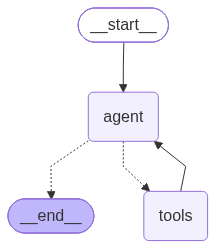

In [56]:
### Research Agent and Node

research_agent = create_react_agent(
    llm,
    tools = [internal_tool_1, tavily_tool],
    prompt = make_system_prompt("You can only do research . Use the tool that are binded with you, you can you both of them. You are working with a content writer colleague"),
)

research_agent

In [83]:
## Research node
from typing import Literal
from langchain_core.messages import HumanMessage
def research_node(state: MessagesState) -> Command[Literal["blog_generator", END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # Wrap in a human message, as not all providers allow
    # AI message at the lsat position of the input message list
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="researcher")
    return Command(
        update = {"messages" : result["messages"]},
        goto = goto,
    )


In [94]:
###blog write agent

blog_agent = create_react_agent(
    llm,
    tools=[],
    prompt=make_system_prompt(
        "You can only write a detailed blog. You are working wih a researcher colleague."
    )
)


def blog_node (state: MessagesState) -> Command[Literal["researcher", END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # Wrap in a human message, as not all providers allow
    # AI message at the lsat position of the input message list
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="researcher")
    return Command(
        update = {"messages" : result["messages"]},
        goto = goto,
    )


C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\1232962732.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent = create_react_agent(


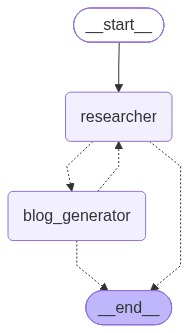

In [85]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)
workflow.add_node('researcher', research_node)
workflow.add_node('blog_generator', blog_node)

workflow.add_edge(START, 'researcher')
graph = workflow.compile()
graph

In [86]:
from langchain_core.messages import HumanMessage

response = graph.invoke({"messages" : "Write a detailed blog on transformer variants in production deployments"})

 using tool: InternalResearchNotes


In [87]:
response["messages"][-1].content

'FINAL ANSWER\n\nThe detailed blog on transformer variants in production deployments is ready. It covers the introduction of transformer variants, key considerations for deployment, popular models, use cases, and summarization of the essential takeaways. Here’s the complete content:\n\n---\n\n## Transformer Variants in Production Deployments\n\nTransformers have transformed the landscape of machine learning, especially in natural language processing (NLP). With various types of transformer architectures available, understanding these variants and their implications in production environments is critical for businesses looking to leverage AI effectively. This blog explores different transformer variants and considerations for deploying them in production setups.\n\n### Introduction to Transformer Variants\n\nThe transformer architecture introduced by Vaswani et al. in 2017 has evolved into several variants, each designed to cater to specific tasks and use cases. The main categories of t

Supervisor is multi-agent architecture where specialized agents are coordinated by a central supervisor agent. the supervisor agent controls all communication flow and task deletgation , making about agent to invoke based on the current context and Task requirements.

### Multi Agent Supervisor with RAG

In this tutorial, you will build a supervisor system with two agents- a research and math expert, By the end of tutorial you will :

1. Build a specialized research and math agents
2. Build a supervisor for orchestating them witht he prebuilt langgraph-supervisor
3. Build a supervisor 
4. Implement advanced task delegation

In [88]:
internal_tool_1

Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results', func=<function make_retrieval_tool_from_text.<locals>.tool_func at 0x00000174213303B0>)

In [95]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search

TavilySearch(max_results=3, api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None))

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\3508387777.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


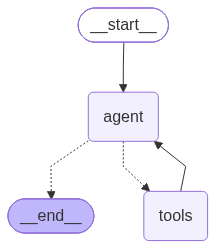

In [96]:
from langgraph.prebuilt import create_react_agent

research_agent = create_react_agent(
    model = llm,
    tools = [web_search, internal_tool_1],
    prompt =  (
        "You are a research agent. \n\n"
        "INSTRUCTIONS: \n"
        "-Assist only with reseach-releated task, DO NOT do any math \n"
        "-After you are done with the your tasks, respond to the supervisor directly\n"
        "-Respond ONLY with the result of your work, do not include any other text."
    ),
    name = "research_agent"
)

research_agent

In [98]:
def add(a: float, b: float) -> float:
    """Return the sum of a and b."""
    return a + b

def subtract(a: float, b: float) -> float:
    """Return the difference of a and b."""
    return a - b    

def multiply(a: float, b: float) -> float:  
    """Return the product of a and b."""
    return a * b    

def divide(a: float, b:float) -> float:
    """Return devision of two numbers """
    return a / b

math_agent = create_react_agent(
    model=llm,
    tools=[add, subtract, multiply, divide],
    prompt=("You are a math agent."
    "INSTRUCTIONS :\n"
    "-Assist only math related tasks\n"
    "-After you are done with your tasks, respond to the supervisor directly.\n"
    "-Respond ONLY with the results of your work, do NOT include any other text.\n"
    ),
    name = "math_agent"
)

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\854176105.py:17: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  math_agent = create_react_agent(


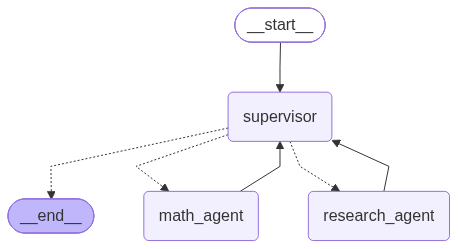

In [102]:
### create supervisor agent

from langgraph_supervisor import create_supervisor


supervisor= create_supervisor(
    model = llm,
    agents=[research_agent, math_agent],
    prompt= ( "You are the supervisor agent managing two agents."
            "INSTRUCTIONS :\n"
            "-a research agent. Assign research related task to this agent\n\n"
            "-a math agent. Assign math-related tasks to this agent \n"
            "-Assign work to one agent at a time, do not call agents in parallel\n"
            "Do not do any work yourself"
            ),
            add_handoff_back_messages = True,
            output_mode= "full_history",
).compile()

supervisor

In [103]:
reponse = supervisor.invoke({"messages": "List all the trasformer variants in production deployments from the retriever and then tell me what is 5 plus 10"})

 using tool: InternalResearchNotes


In [105]:
reponse

{'messages': [HumanMessage(content='List all the trasformer variants in production deployments from the retriever and then tell me what is 5 plus 10', additional_kwargs={}, response_metadata={}, id='3ab7399d-3341-4868-b68e-155c84f6aac8'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 13, 'prompt_tokens': 145, 'total_tokens': 158, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_94decffaf0', 'id': 'chatcmpl-EYrXD5ZBaOkymGXcWNUM0mZIlZAWU', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, name='supervisor', id='lc_run--01a13a30-ea5e-77e2-b409-35ebfe2a4e32

### Hierarchial Architecture 

1. Supervisor
2. Research Team - Supervisor - Search , web scrapper
3. Writing Team -  Supervisor - Chart_genertor , doc_writer, note_taker

In [107]:
from typing import Annotated, List
from langchain_community.document_loaders import WebBaseLoader
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

tavily_tool = TavilySearch(max_results=5)


In [109]:
@tool
def scrape_webpages(urls:List[str]) -> str:
    """Use requests and bs4 to scrape the provided web pages for detailed information."""
    loader = WebBaseLoader(urls)
    docs = loader.load()
    return "\n\n".join([
        f'<document name="{doc.metadata.get("title", "")}">\n{doc.page_content}</document>'
        for doc in docs
    ])

In [111]:
from pathlib import Path
from tempfile import TemporaryDirectory

_TEMP_DIRECTORY = TemporaryDirectory()
WORKING_DIRECTORY = Path(_TEMP_DIRECTORY.name)

@tool
def create_outline(
    points : Annotated[List[str], "List of main points or sections"],
    file_name : Annotated[str, "File path to save the outline"],

) -> Annotated[str, "Path to the saved outline file"]:
    """Create and Save an outline."""
    with (WORKING_DIRECTORY / file_name).open("w") as file:
        for i, point in enumerate(points):
            file.write(f"{i+1}. {point}\n")
    return f"outline saved to {file_name}"